# Listing supply and season

Two features that describe the market rather than the house, tested on top of the best model so far (Random Forest + school districts, from `05_feature_engineering.ipynb`):
- **Listing supply:** the number of active listings and of new listings in the home's ZIP code, from Realtor.com's [monthly inventory data](https://www.realtor.com/research/data/).
- **Season:** the month of the year the home was listed (1–12).

The model predicts a home's close price before it goes on the market, so both features are taken from the **listing** date, not the close date. Supply comes from the month before listing, the latest month Realtor.com has published by then. `05b_evaluation_gap.ipynb` showed that the standard split (train on everything before the evaluation month) gives almost the same scores as cutting training off at each home's listing month, so the standard split is used here.

Setup as before: X = 18 months, compared on the 6 validation months 2025-10 to 2026-03. The test month, 2026-04, is held out and never scored. Neither feature helped, so their code lives in this notebook only.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from idx_exchange_data_science import cleaning as cl
from idx_exchange_data_science import features as ft
from idx_exchange_data_science.modeling import (
    backtest, build_model, feature_importances, fit_window, gain_summary, random_forest,
)
from idx_exchange_data_science.paths import ARCHIVE_DIR, DATA_DIR
from idx_exchange_data_science.preprocessing import make_preprocessor
from idx_exchange_data_science.splits import PRICE_QUANTILES, validation_months

pd.set_option("display.float_format", "{:,.4f}".format)
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

X = 18
EVAL_MONTHS = validation_months("2026-04", n_months=6)  # 2025-10 to 2026-03; 2026-04 is the held-out test month
INVENTORY_PATH = DATA_DIR / "external" / "listing_volume" / "RDC_Inventory_Core_Metrics_Zip_History.csv"
SUPPLY_COLS = ["PrevMonthActiveListings", "PrevMonthNewListings"]
SEASON_COLS = ["ListingMonth"]


def load_zip_inventory(path):
    """Realtor.com monthly ZIP inventory, indexed by (PostalCode, month).

    ZIP codes in the file lost their leading zeros, and some rows have no ZIP name,
    so rows are matched on the padded code rather than filtered by state.
    """
    inventory = pd.read_csv(path, usecols=["month_date_yyyymm", "postal_code", "active_listing_count",
                                           "new_listing_count"], dtype={"postal_code": "string"}, engine="pyarrow")
    return pd.DataFrame({
        "PostalCode": inventory["postal_code"].str.zfill(5),
        "month": pd.PeriodIndex(inventory["month_date_yyyymm"].astype(str), freq="M"),
        "PrevMonthActiveListings": inventory["active_listing_count"],
        "PrevMonthNewListings": inventory["new_listing_count"],
    }).set_index(["PostalCode", "month"])


def add_listing_supply(df, inventory):
    """ZIP inventory in the month before listing. NaN when the listing date is unknown or the
    ZIP-month isn't published (a missing row is not the same as zero listings)."""
    lag_month = df[ft.LISTING_DATE].dt.to_period("M") - 1
    keys = pd.MultiIndex.from_arrays([df["PostalCode"].astype("object"), lag_month])
    supply = inventory.reindex(keys)
    return df.assign(**{col: supply[col].to_numpy(dtype=float) for col in SUPPLY_COLS})


df = add_listing_supply(ft.build_table(), load_zip_inventory(INVENTORY_PATH))
df["ListingMonth"] = df[ft.LISTING_DATE].dt.month.astype(float)
df.shape

(309019, 42)

## 1. Joining the inventory data
Realtor.com's file covers every US ZIP from 2016-07 to 2026-09. Its ZIP codes lost their leading zeros and some rows have no ZIP name, so rows are matched on the zero-padded code, not filtered by state. A ZIP-month that isn't in the file is left missing rather than set to zero, because the file does have explicit zero rows. Missing values are filled with the training-window median, like the other numeric features.

In [2]:
has_date = df[ft.LISTING_DATE].notna()
has_supply = df["PrevMonthActiveListings"].notna()
pd.Series({
    "sales": len(df),
    "no listing date (missing, or over 24 months before close)": (~has_date).sum(),
    "listing date but ZIP-month not published": (has_date & ~has_supply).sum(),
    "share with supply": has_supply.mean(),
}).to_frame("value")

,value
sales,"309,019.0000"
"no listing date (missing, or over 24 months before close)",142.0000
listing date but ZIP-month not published,190.0000
share with supply,0.9989


In [3]:
lo, hi = df[cl.TARGET].quantile(PRICE_QUANTILES)
in_range = df[cl.TARGET].between(lo, hi)
by_listing_month = df[in_range].groupby("ListingMonth").agg(
    sales=(cl.TARGET, "size"), median_price=(cl.TARGET, "median"),
    median_price_per_sqft=(cl.TARGET, lambda p: (p / df.loc[p.index, "LivingArea"]).median()))
by_listing_month

,sales,median_price,median_price_per_sqft
ListingMonth,,,
1.0000,31595,"900,000.0000",537.4109
2.0000,29200,"920,000.0000",549.3061
3.0000,30406,"935,000.0000",554.8345
4.0000,27922,"930,000.0000",548.8398
5.0000,27683,"925,000.0000",547.0014
6.0000,24939,"900,000.0000",536.0624
7.0000,24743,"890,000.0000",530.9530
8.0000,23677,"872,500.0000",521.8565
9.0000,24233,"890,000.0000",532.1508


In [4]:
spearman = df[[*SUPPLY_COLS, "LivingArea"]].corrwith(df[cl.TARGET], method="spearman")
spearman.to_frame("spearman_r")

,spearman_r
PrevMonthActiveListings,-0.2046
PrevMonthNewListings,-0.1352
LivingArea,0.5072


**Observations**
- **The join covers 99.9% of sales.** 142 have no usable listing date and 190 are in a ZIP-month Realtor.com didn't publish. Both are filled with the training median.
- **Raw prices look seasonal by listing month:** homes listed in February–April sell for the most, homes listed in November–December the least (\$487 vs \$555 per sq ft). Part of this is which homes list when, and the model already knows size and location.
- **Supply is only weakly related to price** (Spearman −0.20 for active listings). ZIPs with many listings tend to be cheaper, but that is a property of the ZIP, which the ZIP encoding already captures.

## 2. Feature sets

In [5]:
FEATURE_SETS = {
    "Districts (current best)": [],
    "+ supply": SUPPLY_COLS,
    "+ season": SEASON_COLS,
    "+ supply + season": SUPPLY_COLS + SEASON_COLS,
}
models = {
    name: build_model(random_forest(), make_preprocessor(ft.DISTRICT_NUMERIC_COLS + extra, ft.DISTRICT_COLS))
    for name, extra in FEATURE_SETS.items()
}

## 3. Validation

In [6]:
results, _ = backtest(models, df, EVAL_MONTHS, X)
validation = results.groupby("model")[["r2", "mae", "mape", "median_ape"]].mean().loc[list(FEATURE_SETS)]
validation

,r2,mae,mape,median_ape
model,,,,
Districts (current best),0.8923,"151,207.2719",0.1196,0.0774
+ supply,0.8912,"151,903.6104",0.1201,0.0771
+ season,0.8917,"151,541.9173",0.1200,0.0774
+ supply + season,0.8908,"152,402.2080",0.1206,0.0775


In [7]:
gain_summary(results, reference="Districts (current best)")

,mean gain,std gain,months improved (of 6)
model,,,
+ season,-0.0006,0.0004,1
+ supply,-0.0011,0.0004,0
+ supply + season,-0.0015,0.0005,0


**Observations**
- **Neither feature helps. Both make the model slightly worse:** supply in all 6 validation months, season in 5 of 6, with a small spread (std ≤ 0.0005), so the loss is consistent, not noise. Supply costs 0.0011 R², season 0.0006, both together 0.0015.
- The pattern is the same as the ratio features in `05_feature_engineering.ipynb`: columns that add little new information take split opportunities away from the location features (each split only sees a third of the columns).

## 4. Comparison

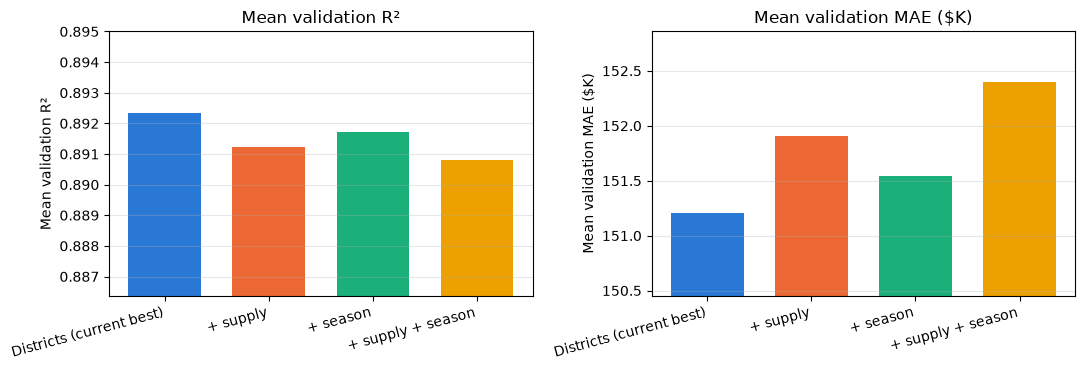

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, metric, label, scale in [(axes[0], "r2", "Mean validation R²", 1), (axes[1], "mae", "Mean validation MAE ($K)", 1000)]:
    values = validation[metric] / scale
    ax.bar(range(len(values)), values, color=COLORS, width=0.7)
    ax.set(xticks=range(len(values)), ylabel=label, title=label)
    ax.set_xticklabels(values.index, rotation=15, ha="right")
    ax.set_ylim(values.min() * 0.995, values.max() * 1.003)
    ax.grid(alpha=0.3, axis="y")
plt.tight_layout()

## 5. Feature importance
Impurity importance from the forest with both new features, fit on the 18 months before 2026-03. A rough ranking only, as in earlier notebooks.

In [9]:
importance = feature_importances(fit_window(models["+ supply + season"], df, EVAL_MONTHS[-1], X)).sort_values(ascending=False)
importance.to_frame("importance").assign(rank=range(1, len(importance) + 1)).loc[
    ["PostalCode", "LivingArea", *SUPPLY_COLS, *SEASON_COLS]]

,importance,rank
PostalCode,0.2904,1
LivingArea,0.1750,2
PrevMonthActiveListings,0.0093,14
PrevMonthNewListings,0.0065,15
ListingMonth,0.0047,17


**Observations**
- **The forest barely uses them.** Active listings rank 14th, new listings 15th, listing month 17th, each with under 1% of importance.
- **Season is mostly already handled.** Training on 18 months covers every season, and the remaining seasonal effect (about 2–3%, see `05b`) is small next to how much prices vary between homes.

## Summary
- **Don't add listing supply or season.** Each lowers validation R² in 5 or 6 of the 6 months.
- **Market-level features have little to offer in this period.** Prices barely moved from 2024 to 2026 (see `05b_evaluation_gap.ipynb`), and how ZIPs differ is already captured by the location encodings.
- **Best model unchanged:** Random Forest + school districts, validation R² 0.892, MAE \$151K.
- Worth revisiting only if the data covers a faster-moving market, where last month's supply could signal where prices are heading.

In [10]:
validation.reset_index().rename(columns={"model": "feature_set"}).to_csv(
    ARCHIVE_DIR / "supply_season_comparison.csv", index=False)
results.to_csv(ARCHIVE_DIR / "supply_season_backtest.csv", index=False)